## Imports and Dataset Loading

In [1]:
# ============================================================
# CODENOVA DATA SCIENCE INTERNSHIP
# TASK 1: SALES DATA ANALYSIS
# ============================================================



## Import Libraries

In [2]:
# STEP 1: IMPORT LIBRARIES

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")




Libraries imported successfully!


## Load Dataset

In [3]:
# STEP 2: LOAD DATASET

file_path = "Copy of codenova_sales_sample.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Dataset not found. Place the CSV file in the "
        "same folder as your Jupyter Notebook, or update file_path."
    )

df = pd.read_csv(file_path)

print("\nDATASET LOADED SUCCESSFULLY")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())





DATASET LOADED SUCCESSFULLY
Number of rows: 360
Number of columns: 12


,Order_ID,Order_Date,Product,Category,Region,Sales_Channel,Customer_Type,Quantity,Unit_Price_INR,Unit_Cost_INR,Discount_Percent,Payment_Method
0,ORD0329,2025-01-02,Water Bottle,Lifestyle,Mumbai,Online,Returning,1,650.0,274.4,0.00,Cash
1,ORD0084,2025-01-03,Office Chair,Furniture,Bengaluru,Retail Store,Returning,2,8925.0,6000.0,0.00,Cash
2,ORD0233,2025-01-04,Smartphone,Electronics,Pune,Online,New,5,18900.0,13770.0,0.15,Cash
3,ORD0110,2025-01-09,Pen Set,Stationery,Bengaluru,Distributor,Returning,4,209.0,91.8,0.05,Credit Card
4,ORD0257,2025-01-10,Backpack,Lifestyle,Mumbai,Online,New,1,1680.0,867.0,0.05,Credit Card


## Explore The Dataset

In [4]:
# STEP 3: EXPLORE THE DATASET

print("\nDATASET INFORMATION")
df.info()

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nSTATISTICAL SUMMARY")
display(df.describe())

print("\nMISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())





DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          360 non-null    object 
 1   Order_Date        360 non-null    object 
 2   Product           360 non-null    object 
 3   Category          360 non-null    object 
 4   Region            360 non-null    object 
 5   Sales_Channel     360 non-null    object 
 6   Customer_Type     360 non-null    object 
 7   Quantity          360 non-null    int64  
 8   Unit_Price_INR    360 non-null    float64
 9   Unit_Cost_INR     360 non-null    float64
 10  Discount_Percent  360 non-null    float64
 11  Payment_Method    360 non-null    object 
dtypes: float64(3), int64(1), object(8)
memory usage: 33.9+ KB

COLUMN NAMES
['Order_ID', 'Order_Date', 'Product', 'Category', 'Region', 'Sales_Channel', 'Customer_Type', 'Quantity', 'Unit_Price_INR', 'Unit_Cost_INR'

,Quantity,Unit_Price_INR,Unit_Cost_INR,Discount_Percent
count,360.000000,360.000000,360.000000,360.000000
mean,2.108333,11806.720833,8982.822222,0.063333
std,1.256487,15575.018903,12547.391177,0.058200
min,1.000000,209.000000,88.200000,0.000000
25%,1.000000,1140.000000,588.000000,0.000000
50%,2.000000,2500.000000,1372.000000,0.050000
75%,3.000000,18000.000000,13500.000000,0.100000
max,5.000000,54600.000000,42840.000000,0.150000



MISSING VALUES


Order_ID            0
Order_Date          0
Product             0
Category            0
Region              0
Sales_Channel       0
Customer_Type       0
Quantity            0
Unit_Price_INR      0
Unit_Cost_INR       0
Discount_Percent    0
Payment_Method      0
dtype: int64


DUPLICATE ROWS
0


## Prepare The Data

In [5]:
# STEP 4: PREPARE THE DATA

# Convert the order date into datetime format

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

# Convert numerical columns to numeric data types

numeric_columns = [
    "Quantity",
    "Unit_Price_INR",
    "Unit_Cost_INR",
    "Discount_Percent"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check for invalid or missing values

print("\nINVALID OR MISSING VALUES")
print("Invalid dates:", df["Order_Date"].isna().sum())

print(
    df[
        numeric_columns
    ].isna().sum()
)

# Keep the original dataset unchanged.
# Create a separate dataset for analysis.

analysis_df = df.dropna(
    subset=[
        "Order_ID",
        "Order_Date",
        "Product",
        "Category",
        "Region",
        "Quantity",
        "Unit_Price_INR",
        "Unit_Cost_INR",
        "Discount_Percent"
    ]
).copy()

# Validate numerical inputs

if (
    (analysis_df["Quantity"] < 0).any()
    or (analysis_df["Unit_Price_INR"] < 0).any()
    or (analysis_df["Unit_Cost_INR"] < 0).any()
):
    raise ValueError(
        "Negative quantity, unit price, or unit cost found. "
        "Investigate these records before continuing."
    )

if not analysis_df["Discount_Percent"].between(0, 1).all():
    raise ValueError(
        "Discount_Percent must be between 0 and 1 "
        "for this calculation."
    )

print("\nValid records available for analysis:", len(analysis_df))





INVALID OR MISSING VALUES
Invalid dates: 0
Quantity            0
Unit_Price_INR      0
Unit_Cost_INR       0
Discount_Percent    0
dtype: int64

Valid records available for analysis: 360


## Calculate Sales, Cost, And Profit

In [6]:
# STEP 5: CALCULATE SALES, COST, AND PROFIT

# Gross sales before discount

analysis_df["Gross_Sales_INR"] = (
    analysis_df["Quantity"]
    * analysis_df["Unit_Price_INR"]
)

# Discount amount

analysis_df["Discount_Amount_INR"] = (
    analysis_df["Gross_Sales_INR"]
    * analysis_df["Discount_Percent"]
)

# Net sales after discount

analysis_df["Net_Sales_INR"] = (
    analysis_df["Gross_Sales_INR"]
    - analysis_df["Discount_Amount_INR"]
)

# Total product cost

analysis_df["Total_Cost_INR"] = (
    analysis_df["Quantity"]
    * analysis_df["Unit_Cost_INR"]
)

# Profit after discount, before other operating expenses

analysis_df["Profit_INR"] = (
    analysis_df["Net_Sales_INR"]
    - analysis_df["Total_Cost_INR"]
)

print("\nCALCULATED SALES DATA")

display(
    analysis_df[
        [
            "Order_ID",
            "Product",
            "Quantity",
            "Gross_Sales_INR",
            "Discount_Amount_INR",
            "Net_Sales_INR",
            "Total_Cost_INR",
            "Profit_INR"
        ]
    ].head()
)





CALCULATED SALES DATA


,Order_ID,Product,Quantity,Gross_Sales_INR,Discount_Amount_INR,Net_Sales_INR,Total_Cost_INR,Profit_INR
0,ORD0329,Water Bottle,1,650.0,0.0,650.0,274.4,375.6
1,ORD0084,Office Chair,2,17850.0,0.0,17850.0,12000.0,5850.0
2,ORD0233,Smartphone,5,94500.0,14175.0,80325.0,68850.0,11475.0
3,ORD0110,Pen Set,4,836.0,41.8,794.2,367.2,427.0
4,ORD0257,Backpack,1,1680.0,84.0,1596.0,867.0,729.0


## Calculate Key Business Metrics

In [7]:
# STEP 6: CALCULATE KEY BUSINESS METRICS

total_gross_revenue = analysis_df["Gross_Sales_INR"].sum()

total_discount = analysis_df["Discount_Amount_INR"].sum()

total_net_sales = analysis_df["Net_Sales_INR"].sum()

total_cost = analysis_df["Total_Cost_INR"].sum()

total_profit = analysis_df["Profit_INR"].sum()

total_orders = analysis_df["Order_ID"].nunique()

total_units_sold = analysis_df["Quantity"].sum()

average_order_value = (
    total_net_sales / total_orders
    if total_orders > 0
    else np.nan
)

profit_margin = (
    total_profit / total_net_sales * 100
    if total_net_sales != 0
    else np.nan
)

metrics = pd.DataFrame({
    "Metric": [
        "Total Gross Revenue Before Discount (INR)",
        "Total Discount (INR)",
        "Total Net Sales After Discount (INR)",
        "Total Product Cost (INR)",
        "Total Profit (INR)",
        "Profit Margin (%)",
        "Total Orders",
        "Average Order Value (INR)",
        "Total Units Sold"
    ],
    "Value": [
        total_gross_revenue,
        total_discount,
        total_net_sales,
        total_cost,
        total_profit,
        profit_margin,
        total_orders,
        average_order_value,
        total_units_sold
    ]
})

print("\nKEY BUSINESS METRICS")

display(metrics.round(2))





KEY BUSINESS METRICS


,Metric,Value
0,Total Gross Revenue Before Discount (INR),8560413.00
1,Total Discount (INR),534927.85
2,Total Net Sales After Discount (INR),8025485.15
3,Total Product Cost (INR),6483694.60
4,Total Profit (INR),1541790.55
5,Profit Margin (%),19.21
6,Total Orders,360.00
7,Average Order Value (INR),22293.01
8,Total Units Sold,759.00


## Category-Wise Sales And Profit Analysis

In [8]:
# STEP 7: CATEGORY-WISE SALES AND PROFIT ANALYSIS

category_analysis = analysis_df.groupby("Category").agg(
    Total_Gross_Revenue=("Gross_Sales_INR", "sum"),
    Total_Discount=("Discount_Amount_INR", "sum"),
    Total_Net_Sales=("Net_Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Units_Sold=("Quantity", "sum")
)

category_analysis["Profit_Margin_Percent"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Net_Sales"].replace(0, np.nan)
) * 100

category_analysis = category_analysis.sort_values(
    "Total_Net_Sales",
    ascending=False
)

print("\nCATEGORY-WISE ANALYSIS")

display(category_analysis.round(2))





CATEGORY-WISE ANALYSIS


,Total_Gross_Revenue,Total_Discount,Total_Net_Sales,Total_Profit,Units_Sold,Profit_Margin_Percent
Category,,,,,,
Electronics,6675000.0,410325.00,6264675.00,1042575.00,215,16.64
Furniture,1404225.0,97340.00,1306885.00,293789.00,134,22.48
Accessories,315615.0,16729.75,298885.25,132114.25,181,44.20
Lifestyle,136310.0,8648.75,127661.25,59890.85,126,46.91
Stationery,29263.0,1884.35,27378.65,13421.45,103,49.02


## Category-Wise Sales Chart

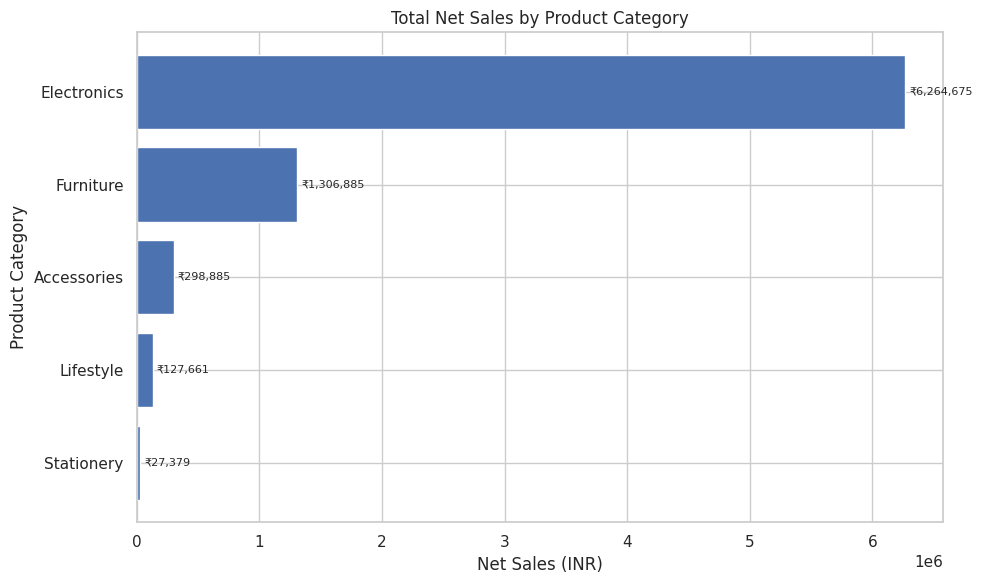

In [9]:
os.makedirs("charts", exist_ok=True)
plot_data = category_analysis.sort_values("Total_Net_Sales", ascending=True)
plt.figure(figsize=(10, 6))
bars = plt.barh(plot_data.index, plot_data["Total_Net_Sales"])
plt.bar_label(bars, labels=[f"₹{v:,.0f}" for v in plot_data["Total_Net_Sales"]], padding=3, fontsize=8)
plt.title("Total Net Sales by Product Category")
plt.xlabel("Net Sales (INR)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig("charts/category_sales.png", dpi=300, bbox_inches="tight")
plt.show()


## Category-Wise Profit Chart

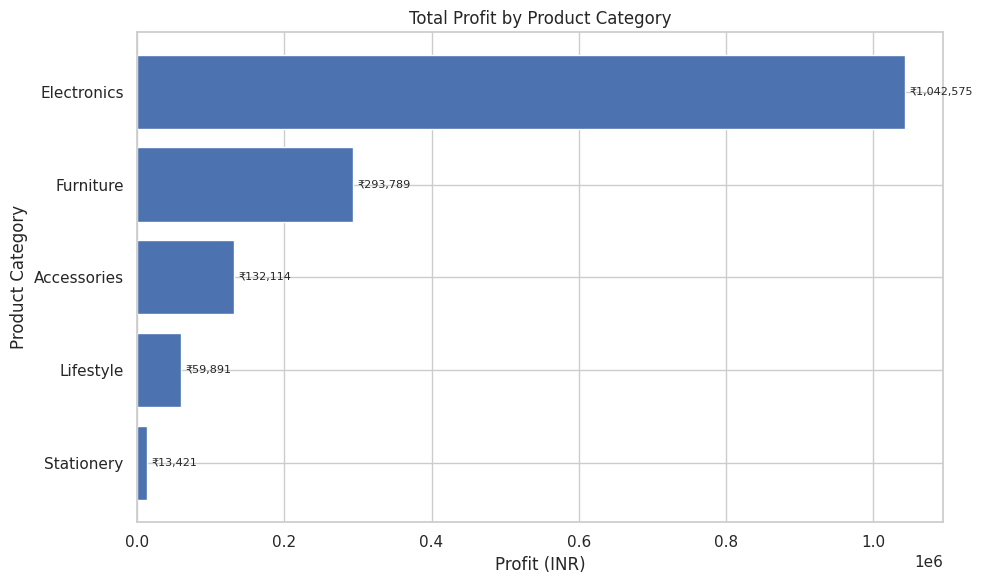

In [10]:
os.makedirs("charts", exist_ok=True)
plot_data = category_analysis.sort_values("Total_Profit", ascending=True)
plt.figure(figsize=(10, 6))
bars = plt.barh(plot_data.index, plot_data["Total_Profit"])
plt.bar_label(bars, labels=[f"₹{v:,.0f}" for v in plot_data["Total_Profit"]], padding=3, fontsize=8)
plt.title("Total Profit by Product Category")
plt.xlabel("Profit (INR)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig("charts/category_profit.png", dpi=300, bbox_inches="tight")
plt.show()


## Product Performance Analysis

In [11]:
# STEP 10: PRODUCT PERFORMANCE ANALYSIS

product_analysis = analysis_df.groupby("Product").agg(
    Total_Net_Sales=("Net_Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Units_Sold=("Quantity", "sum")
)

product_analysis["Profit_Margin_Percent"] = (
    product_analysis["Total_Profit"]
    / product_analysis["Total_Net_Sales"].replace(0, np.nan)
) * 100

print("\nTOP 10 PRODUCTS BY SALES")

display(
    product_analysis.sort_values(
        "Total_Net_Sales",
        ascending=False
    ).head(10).round(2)
)

print("\nTOP 10 PRODUCTS BY PROFIT")

display(
    product_analysis.sort_values(
        "Total_Profit",
        ascending=False
    ).head(10).round(2)
)





TOP 10 PRODUCTS BY SALES


,Total_Net_Sales,Total_Profit,Units_Sold,Profit_Margin_Percent
Product,,,,
Laptop,3283410.00,470250.00,67,14.32
Tablet,1863060.00,344580.00,82,18.50
Smartphone,1118205.00,227745.00,66,20.37
Desk,814650.00,167674.00,73,20.58
Office Chair,492235.00,126115.00,61,25.62
Keyboard,120510.00,52927.00,71,43.92
Headphones,103456.25,44936.25,42,43.44
Backpack,86032.00,37548.00,57,43.64
Wireless Mouse,74919.00,34251.00,68,45.72



TOP 10 PRODUCTS BY PROFIT


,Total_Net_Sales,Total_Profit,Units_Sold,Profit_Margin_Percent
Product,,,,
Laptop,3283410.00,470250.00,67,14.32
Tablet,1863060.00,344580.00,82,18.50
Smartphone,1118205.00,227745.00,66,20.37
Desk,814650.00,167674.00,73,20.58
Office Chair,492235.00,126115.00,61,25.62
Keyboard,120510.00,52927.00,71,43.92
Headphones,103456.25,44936.25,42,43.44
Backpack,86032.00,37548.00,57,43.64
Wireless Mouse,74919.00,34251.00,68,45.72


## High-Margin Product Ranking
This ranks products by profit margin separately from total sales and total profit.


PRODUCTS RANKED BY PROFIT MARGIN


,Total_Net_Sales,Total_Profit,Units_Sold,Profit_Margin_Percent
Product,,,,
Pen Set,10396.65,5889.45,50,56.65
Water Bottle,41629.25,22342.85,69,53.67
Wireless Mouse,74919.00,34251.00,68,45.72
Notebook Pack,16982.00,7532.00,53,44.35
Keyboard,120510.00,52927.00,71,43.92
Backpack,86032.00,37548.00,57,43.64
Headphones,103456.25,44936.25,42,43.44
Office Chair,492235.00,126115.00,61,25.62
Desk,814650.00,167674.00,73,20.58


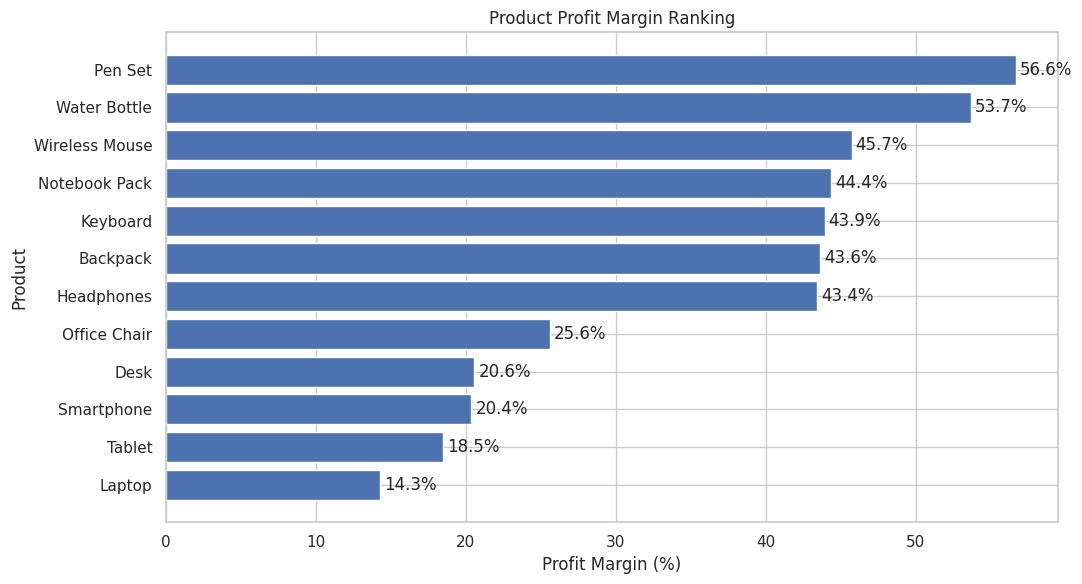

In [12]:
high_margin_products = product_analysis.sort_values("Profit_Margin_Percent", ascending=False)
print("PRODUCTS RANKED BY PROFIT MARGIN")
display(high_margin_products[["Total_Net_Sales", "Total_Profit", "Units_Sold", "Profit_Margin_Percent"]].round(2))

plt.figure(figsize=(11, 6))
margin_plot = high_margin_products.sort_values("Profit_Margin_Percent", ascending=True)
bars = plt.barh(margin_plot.index, margin_plot["Profit_Margin_Percent"])
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Product Profit Margin Ranking")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("charts/product_profit_margin.png", dpi=300, bbox_inches="tight")
plt.show()


## Monthly Sales Trend


MONTHLY SALES


Year_Month
2025-01    608920.200
2025-02    177132.500
2025-03    438515.250
2025-04    454722.875
2025-05    415679.500
2025-06    264817.375
2025-07    324740.250
2025-08    266203.225
2025-09    147502.500
2025-10    381267.100
2025-11    379722.900
2025-12    467159.000
2026-01    297868.500
2026-02    393139.000
2026-03    902649.050
2026-04    342477.750
2026-05    631182.375
2026-06    243276.050
2026-07    407667.250
2026-08    148244.000
2026-09    332598.500
Freq: M, Name: Net_Sales_INR, dtype: float64

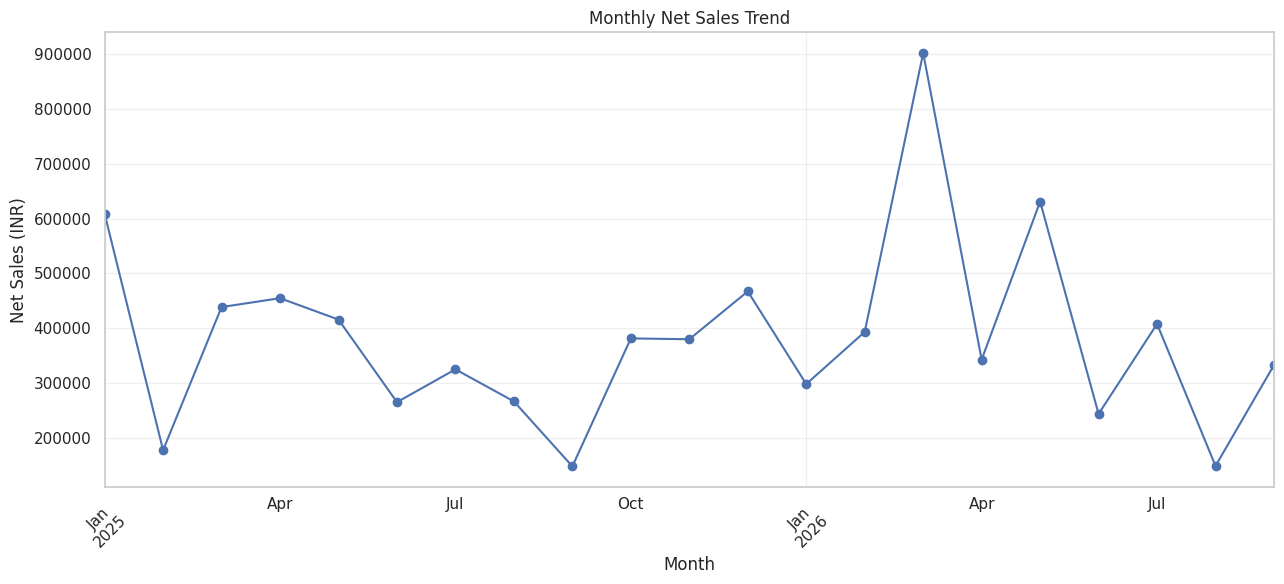

Highest Sales Month: 2026-03
Highest Monthly Sales: 902649.05
Lowest Sales Month: 2025-09
Lowest Monthly Sales: 147502.5


In [13]:
# STEP 11: MONTHLY SALES TREND

analysis_df["Year_Month"] = (
    analysis_df["Order_Date"].dt.to_period("M")
)

monthly_sales = analysis_df.groupby(
    "Year_Month"
)["Net_Sales_INR"].sum()

print("\nMONTHLY SALES")

display(monthly_sales)

plt.figure(figsize=(13, 6))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "charts/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Monthly Sales:", round(monthly_sales.max(), 2))

print("Lowest Sales Month:", monthly_sales.idxmin())
print("Lowest Monthly Sales:", round(monthly_sales.min(), 2))




## Quarterly Sales Analysis


QUARTERLY SALES


Quarter
2025Q1    1224567.950
2025Q2    1135219.750
2025Q3     738445.975
2025Q4    1228149.000
2026Q1    1593656.550
2026Q2    1216936.175
2026Q3     888509.750
Freq: Q-DEC, Name: Net_Sales_INR, dtype: float64

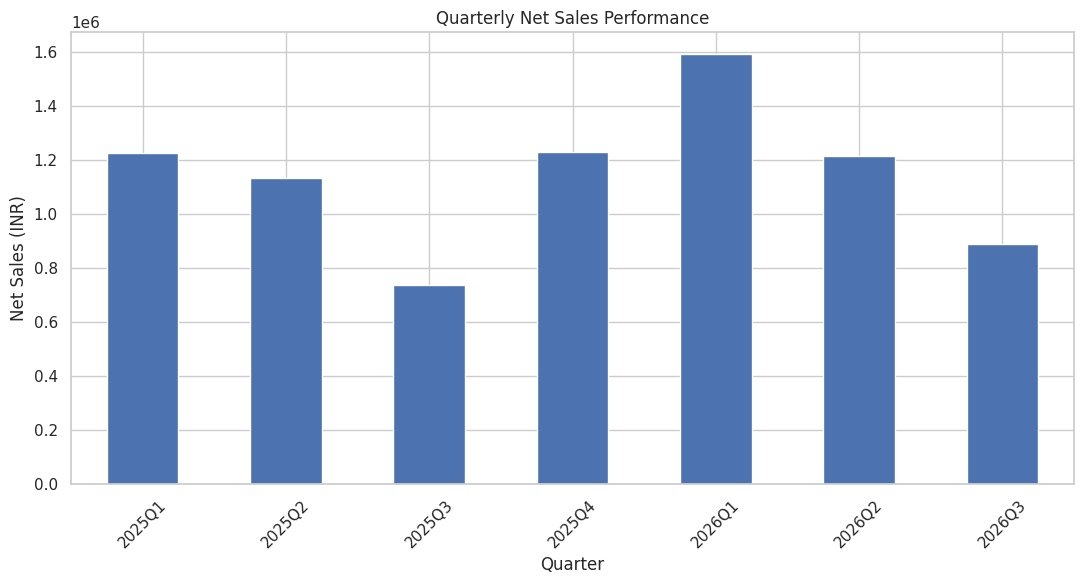

In [14]:
# STEP 12: QUARTERLY SALES ANALYSIS

analysis_df["Quarter"] = (
    analysis_df["Order_Date"].dt.to_period("Q")
)

quarterly_sales = analysis_df.groupby(
    "Quarter"
)["Net_Sales_INR"].sum()

print("\nQUARTERLY SALES")

display(quarterly_sales)

plt.figure(figsize=(11, 6))

quarterly_sales.plot(kind="bar")

plt.title("Quarterly Net Sales Performance")
plt.xlabel("Quarter")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "charts/quarterly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




## Seasonal and Month-of-Year Analysis
This compares total sales by calendar month and displays the year-month trend. Less than two full years of data cannot prove recurring seasonality.


TOTAL NET SALES BY CALENDAR MONTH (COMBINED AVAILABLE YEARS)


,Total_Net_Sales_INR
Jan,906788.70
Feb,570271.50
Mar,1341164.30
Apr,797200.62
May,1046861.88
Jun,508093.42
Jul,732407.50
Aug,414447.22
Sep,480101.00
Oct,381267.10


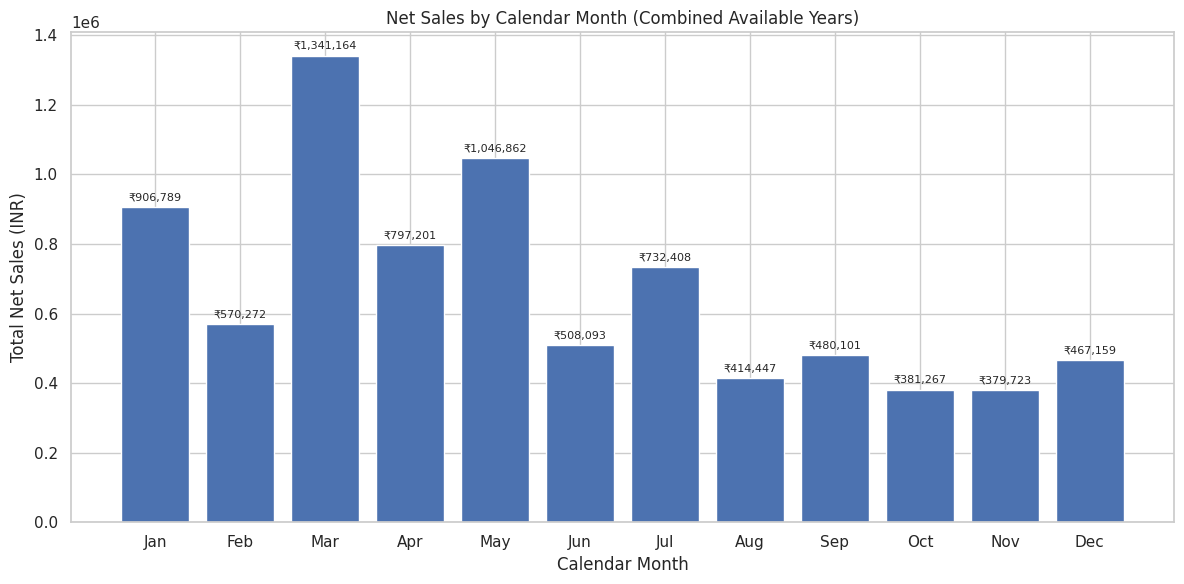

YEAR-MONTH SALES COMPARISON


,Net_Sales_INR
Year_Month,
2025-01,608920.20
2025-02,177132.50
2025-03,438515.25
2025-04,454722.88
2025-05,415679.50
2025-06,264817.38
2025-07,324740.25
2025-08,266203.22
2025-09,147502.50


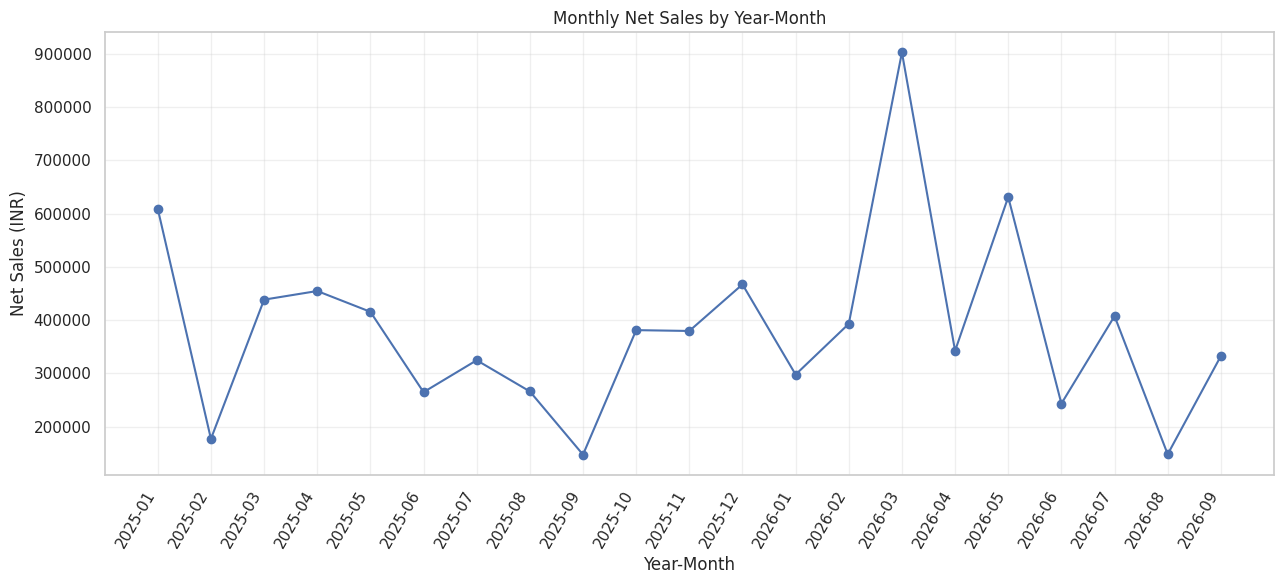

Highest-sales month: 2026-03 | Net sales: 902649.05
Lowest-sales month: 2025-09 | Net sales: 147502.5


In [15]:
analysis_df["Month_Number"] = analysis_df["Order_Date"].dt.month
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_of_year = analysis_df.groupby("Month_Number")["Net_Sales_INR"].sum().reindex(range(1, 13), fill_value=0)
monthly_of_year.index = month_names
print("TOTAL NET SALES BY CALENDAR MONTH (COMBINED AVAILABLE YEARS)")
display(monthly_of_year.to_frame("Total_Net_Sales_INR").round(2))
plt.figure(figsize=(12, 6))
bars = plt.bar(monthly_of_year.index, monthly_of_year.values)
plt.bar_label(bars, labels=[f"₹{v:,.0f}" for v in monthly_of_year.values], padding=3, fontsize=8)
plt.title("Net Sales by Calendar Month (Combined Available Years)")
plt.xlabel("Calendar Month")
plt.ylabel("Total Net Sales (INR)")
plt.tight_layout()
plt.savefig("charts/seasonal_sales.png", dpi=300, bbox_inches="tight")
plt.show()

analysis_df["Year_Month"] = analysis_df["Order_Date"].dt.to_period("M")
monthly_sales = analysis_df.groupby("Year_Month")["Net_Sales_INR"].sum().sort_index()
print("YEAR-MONTH SALES COMPARISON")
display(monthly_sales.to_frame("Net_Sales_INR").round(2))
plt.figure(figsize=(13, 6))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Net Sales by Year-Month")
plt.xlabel("Year-Month")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=60, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("charts/monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()
print("Highest-sales month:", monthly_sales.idxmax(), "| Net sales:", round(monthly_sales.max(), 2))
print("Lowest-sales month:", monthly_sales.idxmin(), "| Net sales:", round(monthly_sales.min(), 2))


## Regional Sales Analysis


REGIONAL ANALYSIS


,Total_Net_Sales,Total_Profit,Units_Sold,Profit_Margin_Percent
Region,,,,
Bengaluru,1558069.90,303538.10,144,19.48
Chennai,802560.12,172893.32,111,21.54
Delhi,1581289.25,318614.65,141,20.15
Hyderabad,699204.52,147868.92,77,21.15
Mumbai,1613076.85,277597.65,135,17.21
Pune,1771284.50,321277.90,151,18.14


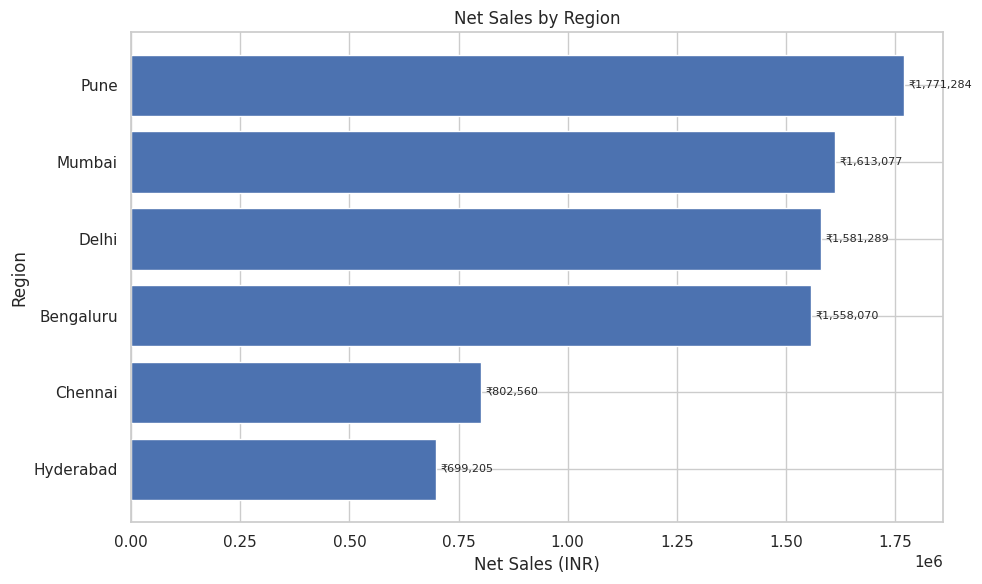

In [16]:
# STEP 14: REGIONAL SALES ANALYSIS

region_analysis = analysis_df.groupby("Region").agg(
    Total_Net_Sales=("Net_Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Units_Sold=("Quantity", "sum")
)

region_analysis["Profit_Margin_Percent"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Net_Sales"].replace(0, np.nan)
) * 100

print("\nREGIONAL ANALYSIS")

display(region_analysis.round(2))

plot_data = region_analysis.sort_values("Total_Net_Sales", ascending=True)
plt.figure(figsize=(10, 6))
bars = plt.barh(plot_data.index, plot_data["Total_Net_Sales"])
plt.bar_label(bars, labels=[f"₹{v:,.0f}" for v in plot_data["Total_Net_Sales"]], padding=3, fontsize=8)
plt.title("Net Sales by Region")
plt.xlabel("Net Sales (INR)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("charts/regional_sales.png", dpi=300, bbox_inches="tight")
plt.show()


## Sales Channel Analysis


SALES CHANNEL ANALYSIS


,Total_Net_Sales,Total_Profit,Total_Orders
Sales_Channel,,,
Distributor,2635889.17,467104.98,115
Online,2611361.38,528271.38,132
Retail Store,2778234.60,546414.20,113


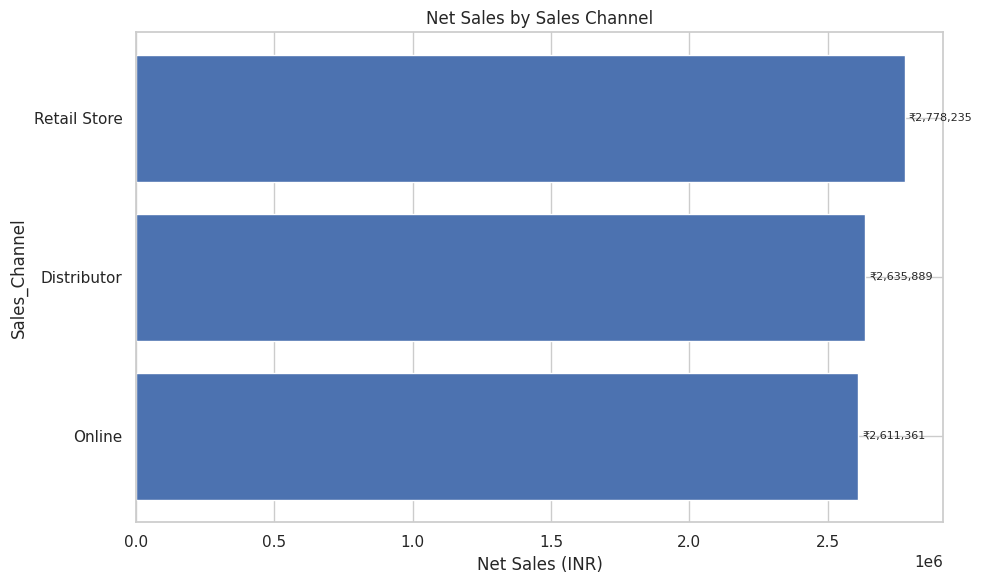

In [17]:
# STEP 15: SALES CHANNEL ANALYSIS

channel_analysis = analysis_df.groupby("Sales_Channel").agg(
    Total_Net_Sales=("Net_Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Total_Orders=("Order_ID", "nunique")
)

print("\nSALES CHANNEL ANALYSIS")

display(channel_analysis.round(2))

plot_data = channel_analysis.sort_values("Total_Net_Sales", ascending=True)
plt.figure(figsize=(10, 6))
bars = plt.barh(plot_data.index, plot_data["Total_Net_Sales"])
plt.bar_label(bars, labels=[f"₹{v:,.0f}" for v in plot_data["Total_Net_Sales"]], padding=3, fontsize=8)
plt.title("Net Sales by Sales Channel")
plt.xlabel("Net Sales (INR)")
plt.ylabel("Sales_Channel")
plt.tight_layout()
plt.savefig("charts/channel_sales.png", dpi=300, bbox_inches="tight")
plt.show()


## Customer Type Analysis

In [18]:
# STEP 16: CUSTOMER TYPE ANALYSIS

customer_analysis = analysis_df.groupby("Customer_Type").agg(
    Total_Net_Sales=("Net_Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Total_Orders=("Order_ID", "nunique")
)

print("\nCUSTOMER TYPE ANALYSIS")

display(customer_analysis.round(2))





CUSTOMER TYPE ANALYSIS


,Total_Net_Sales,Total_Profit,Total_Orders
Customer_Type,,,
New,3953003.25,775853.65,176
Returning,4072481.90,765936.90,184


## Payment Method Analysis

In [19]:
# STEP 17: PAYMENT METHOD ANALYSIS

payment_analysis = analysis_df.groupby("Payment_Method").agg(
    Total_Net_Sales=("Net_Sales_INR", "sum"),
    Total_Orders=("Order_ID", "nunique")
)

print("\nPAYMENT METHOD ANALYSIS")

display(payment_analysis.round(2))





PAYMENT METHOD ANALYSIS


,Total_Net_Sales,Total_Orders
Payment_Method,,
Cash,1963176.00,72
Credit Card,1389296.95,70
Debit Card,1450871.90,76
Net Banking,1880962.12,75
UPI,1341178.18,67


## Financial Validation

In [20]:
# STEP 18: FINANCIAL VALIDATION

print("\nFINANCIAL VALIDATION")

print(
    "Gross revenue equals net sales plus discounts:",
    np.isclose(
        total_gross_revenue,
        total_net_sales + total_discount
    )
)

print(
    "Net sales equal profit plus product cost:",
    np.isclose(
        total_net_sales,
        total_profit + total_cost
    )
)

print(
    "Category sales reconcile with total sales:",
    np.isclose(
        category_analysis["Total_Net_Sales"].sum(),
        total_net_sales
    )
)

print(
    "Category profit reconciles with total profit:",
    np.isclose(
        category_analysis["Total_Profit"].sum(),
        total_profit
    )
)

print(
    "Regional sales reconcile with total sales:",
    np.isclose(
        region_analysis["Total_Net_Sales"].sum(),
        total_net_sales
    )
)





FINANCIAL VALIDATION
Gross revenue equals net sales plus discounts: True
Net sales equal profit plus product cost: True
Category sales reconcile with total sales: True
Category profit reconciles with total profit: True
Regional sales reconcile with total sales: True


## Automatic Business Summary

In [21]:
# STEP 19: AUTOMATIC BUSINESS SUMMARY

best_sales_category = category_analysis[
    "Total_Net_Sales"
].idxmax()

best_profit_category = category_analysis[
    "Total_Profit"
].idxmax()

best_sales_product = product_analysis[
    "Total_Net_Sales"
].idxmax()

best_profit_product = product_analysis[
    "Total_Profit"
].idxmax()

best_sales_region = region_analysis[
    "Total_Net_Sales"
].idxmax()

best_sales_channel = channel_analysis[
    "Total_Net_Sales"
].idxmax()

print("\n" + "=" * 60)
print("SALES DATA ANALYSIS: BUSINESS SUMMARY")
print("=" * 60)

print(f"Total Gross Revenue: INR {total_gross_revenue:,.2f}")
print(f"Total Discounts: INR {total_discount:,.2f}")
print(f"Total Net Sales: INR {total_net_sales:,.2f}")
print(f"Total Product Cost: INR {total_cost:,.2f}")
print(f"Total Profit: INR {total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: INR {average_order_value:,.2f}")
print(f"Total Units Sold: {total_units_sold:,}")

print("\nTOP PERFORMERS")

print("Highest Sales Category:", best_sales_category)
print("Highest Profit Category:", best_profit_category)
print("Highest Sales Product:", best_sales_product)
print("Highest Profit Product:", best_profit_product)
print("Highest Sales Region:", best_sales_region)
print("Highest Sales Channel:", best_sales_channel)
print("Highest Sales Month:", monthly_sales.idxmax())

print("\nCharts saved in the 'charts' folder.")

print("\nSALES DATA ANALYSIS COMPLETED SUCCESSFULLY!")


SALES DATA ANALYSIS: BUSINESS SUMMARY
Total Gross Revenue: INR 8,560,413.00
Total Discounts: INR 534,927.85
Total Net Sales: INR 8,025,485.15
Total Product Cost: INR 6,483,694.60
Total Profit: INR 1,541,790.55
Profit Margin: 19.21%
Total Orders: 360
Average Order Value: INR 22,293.01
Total Units Sold: 759

TOP PERFORMERS
Highest Sales Category: Electronics
Highest Profit Category: Electronics
Highest Sales Product: Laptop
Highest Profit Product: Laptop
Highest Sales Region: Pune
Highest Sales Channel: Retail Store
Highest Sales Month: 2026-03

Charts saved in the 'charts' folder.

SALES DATA ANALYSIS COMPLETED SUCCESSFULLY!


## Business Insights and Strategic Recommendations

These insights are generated from calculated tables, rather than hard-coded findings. Compare sales, total profit, and profit margin together because they measure different things. One peak month does not prove seasonality; additional years of data are needed to confirm recurring patterns.


In [22]:
best_sales_category = category_analysis["Total_Net_Sales"].idxmax()
best_profit_category = category_analysis["Total_Profit"].idxmax()
best_sales_product = product_analysis["Total_Net_Sales"].idxmax()
best_profit_product = product_analysis["Total_Profit"].idxmax()
best_margin_product = product_analysis["Profit_Margin_Percent"].idxmax()
best_sales_region = region_analysis["Total_Net_Sales"].idxmax()
best_sales_channel = channel_analysis["Total_Net_Sales"].idxmax()

print("BUSINESS INSIGHTS")
print(f"1. Total net sales were ₹{total_net_sales:,.2f}, with total profit of ₹{total_profit:,.2f}.")
print(f"2. Overall profit margin was {profit_margin:.2f}%.")
print(f"3. {best_sales_category} generated the highest net sales by category.")
print(f"4. {best_profit_category} generated the highest total profit by category.")
print(f"5. {best_sales_product} generated the highest net sales among products.")
print(f"6. {best_profit_product} generated the highest total profit among products.")
print(f"7. {best_margin_product} had the highest profit margin ({product_analysis.loc[best_margin_product, 'Profit_Margin_Percent']:.2f}%).")
print(f"8. {best_sales_region} had the highest regional net sales.")
print(f"9. {best_sales_channel} had the highest net sales among sales channels.")
print("\nSTRATEGIC RECOMMENDATIONS")
print("1. Monitor inventory for top-selling products to reduce stockouts.")
print("2. Test promotions or bundles for high-margin products without eroding margins.")
print("3. Investigate lower-performing categories and regions before reallocating marketing spend.")
print("4. Compare profit as well as sales when evaluating sales channels.")
print("5. Collect more years of data before making strong seasonal or forecasting claims.")


BUSINESS INSIGHTS
1. Total net sales were ₹8,025,485.15, with total profit of ₹1,541,790.55.
2. Overall profit margin was 19.21%.
3. Electronics generated the highest net sales by category.
4. Electronics generated the highest total profit by category.
5. Laptop generated the highest net sales among products.
6. Laptop generated the highest total profit among products.
7. Pen Set had the highest profit margin (56.65%).
8. Pune had the highest regional net sales.
9. Retail Store had the highest net sales among sales channels.

STRATEGIC RECOMMENDATIONS
1. Monitor inventory for top-selling products to reduce stockouts.
2. Test promotions or bundles for high-margin products without eroding margins.
3. Investigate lower-performing categories and regions before reallocating marketing spend.
4. Compare profit as well as sales when evaluating sales channels.
5. Collect more years of data before making strong seasonal or forecasting claims.


## Conclusion

This analysis calculates core sales and profitability metrics, compares category and product performance, examines monthly and quarterly trends, and visualizes regional and channel performance. Use the findings to guide inventory and marketing tests, then evaluate those decisions with future sales data.
